In [1]:
from Board import DartBoard
import cv2
import matplotlib.pyplot as plt
import numpy as np
%load_ext autoreload
%autoreload 2

In [2]:

"""Play original and processed video side by side. Press q to quit."""

import cv2
import numpy as np
from Board import DartBoard

VIDEO_PATH = r"..\data\videos\white_background_yesHuman.mp4"

DISPLAY_WIDTH = 640
DISPLAY_HEIGHT = 640
RETRY_EVERY_N_FRAMES = 30
CACHE_BOARD = True
CAMERA_ON = True
INIT_FRAMES = []


def main():
    frame_count = 0
    init_frames = []
    board = DartBoard()

    if CAMERA_ON:
        PATH = 1
    else:
        PATH = VIDEO_PATH

    cap = cv2.VideoCapture(PATH)

    if not cap.isOpened():
        cap.release()
        raise FileNotFoundError(f"Cannot open video: {PATH}")

    try:
        once_frame = False
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            if not once_frame:
                reference_frame = frame.copy()
                once_frame = True
            else:
                difference = cv2.absdiff(frame, reference_frame)
                mean_difference = np.mean(difference) / 255.0
                if mean_difference > 0.01:
                    reference_frame = frame.copy()
            original = reference_frame.copy()
            # else:
            #     original = frame.copy()

            board.update_frame(frame)
            frame_count += 1

            if len(init_frames) < 10:
                init_frames.append(frame.copy())
                print(f"Collected Initial Frames: {len(init_frames)}")

                if len(init_frames) == 10:
                    board.calibrate(init_frames)

            if board.board_homography is not None:
                if (
                    not CACHE_BOARD
                    or board.field_map is None
                    or frame_count % RETRY_EVERY_N_FRAMES == 0
                ):
                    board.detect()

                processed = board.draw()
            else:
                processed = board.frame.copy()

            # Resize both outputs
            original = cv2.resize(
                original, (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            processed = cv2.resize(
                processed, (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            if len(processed.shape) == 2:
                processed = cv2.cvtColor(
                    processed, cv2.COLOR_GRAY2BGR
                )

            cv2.putText(
                original, "Original",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                1, (0, 255, 0), 2
            )

            cv2.putText(
                processed, "Processed",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                1, (0, 255, 0), 2
            )

            # Combine frames horizontally
            combined = np.hstack((original, processed))

            cv2.imshow("Original | Processed", combined)

            if cv2.waitKey(5) & 0xFF == ord("q"):
                break

    finally:
        cap.release()
        cv2.destroyAllWindows()


if __name__ == "__main__":
    main()


Collected Initial Frames: 1
Collected Initial Frames: 2
Collected Initial Frames: 3
Collected Initial Frames: 4
Collected Initial Frames: 5
Collected Initial Frames: 6
Collected Initial Frames: 7
Collected Initial Frames: 8
Collected Initial Frames: 9
Collected Initial Frames: 10


In [3]:

"""Record frame differences to determine an optimal detection threshold.

SPACE = Mark a dart landing
R     = Reset reference frame
Q     = Quit and save
"""

import cv2
import numpy as np
import csv
import time

VIDEO_PATH = r"..\data\videos\white_background_yesHuman.mp4"
CAMERA_ON = True
CAMERA_INDEX = 0

DISPLAY_WIDTH = 640
DISPLAY_HEIGHT = 640

CSV_PATH = "frame_differences.csv"


def main():
    path = CAMERA_INDEX if CAMERA_ON else VIDEO_PATH
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    reference_frame = None
    measurements = []
    frame_count = 0
    max_difference = 0.0
    start_time = time.time()

    try:
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame_count += 1

            if reference_frame is None:
                reference_frame = frame.copy()

            # Calculate frame difference
            difference = cv2.absdiff(frame, reference_frame)
            gray_difference = cv2.cvtColor(
                difference, cv2.COLOR_BGR2GRAY
            )

            mean_difference = float(np.mean(difference))
            max_pixel_difference = int(np.max(gray_difference))

            # Percentage of pixels changed significantly
            changed_percentage = float(
                np.mean(gray_difference > 30) * 100
            )

            max_difference = max(
                max_difference, mean_difference
            )

            timestamp = time.time() - start_time

            # Store measurements
            measurement = {
                "frame": frame_count,
                "time": round(timestamp, 3),
                "mean_difference": round(mean_difference, 3),
                "max_pixel_difference": max_pixel_difference,
                "changed_percentage": round(changed_percentage, 3),
                "dart_landed": 0
            }

            measurements.append(measurement)

            # Prepare display
            original_display = cv2.resize(
                frame.copy(),
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.resize(
                gray_difference,
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.cvtColor(
                difference_display, cv2.COLOR_GRAY2BGR
            )

            # Display measurements
            cv2.putText(
                original_display,
                f"Mean difference: {mean_difference:.2f}",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Max difference: {max_difference:.2f}",
                (20, 80),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Changed pixels: {changed_percentage:.2f}%",
                (20, 120),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            combined = np.hstack(
                (original_display, difference_display)
            )

            cv2.imshow("Frame Difference Analysis", combined)

            key = cv2.waitKey(5) & 0xFF

            if key == ord("q"):
                break

            elif key == ord("r"):
                
                reference_frame = frame.copy()
                print("Reference frame reset")

            elif key == 32:
                measurements[-1]["dart_landed"] = 1
                print(
                    f"Dart marked at frame {frame_count}, "
                    f"difference = {mean_difference:.2f}"
                )

    finally:
        cap.release()
        cv2.destroyAllWindows()

        # Save measurements
        if measurements:
            with open(CSV_PATH, "w", newline="") as file:
                writer = csv.DictWriter(
                    file,
                    fieldnames=measurements[0].keys()
                )
                writer.writeheader()
                writer.writerows(measurements)

            print(f"\nMeasurements saved to {CSV_PATH}")
            print(f"Maximum mean difference: {max_difference:.2f}")


if __name__ == "__main__":
    main()


Reference frame reset
Dart marked at frame 452, difference = 1.99
Reference frame reset
Dart marked at frame 575, difference = 1.78
Reference frame reset
Dart marked at frame 662, difference = 1.88
Reference frame reset

Measurements saved to frame_differences.csv
Maximum mean difference: 56.23


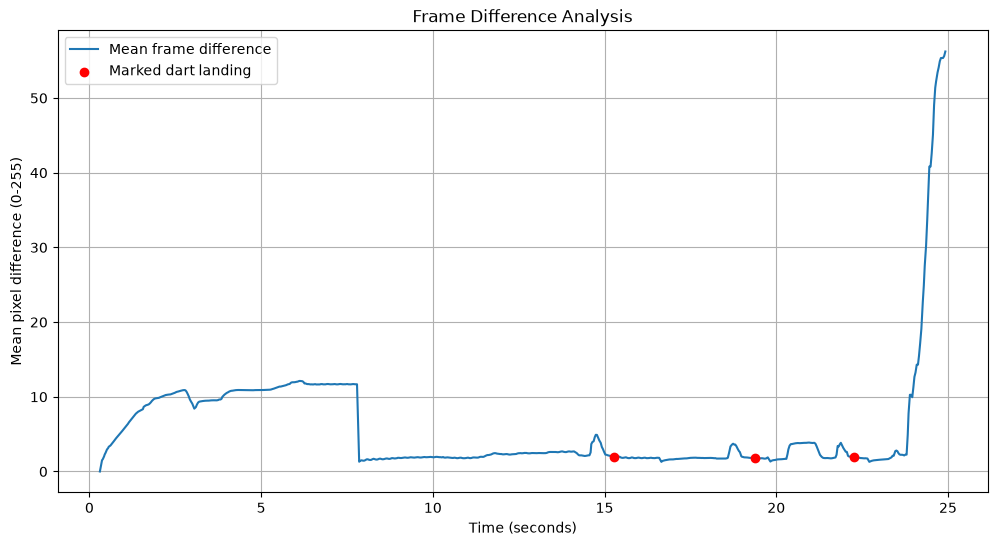

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("frame_differences.csv")

plt.figure(figsize=(12, 6))

plt.plot(
    df["time"],
    df["mean_difference"],
    label="Mean frame difference"
)

# Mark dart landing events
dart_events = df[df["dart_landed"] == 1]

plt.scatter(
    dart_events["time"],
    dart_events["mean_difference"],
    color="red",
    label="Marked dart landing",
    zorder=5
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean pixel difference (0-255)")
plt.title("Frame Difference Analysis")
plt.legend()
plt.grid(True)
plt.show()


# Event detection on recorded video

In [5]:

"""Record frame differences to determine an optimal detection threshold.

SPACE = Mark a dart landing
R     = Reset reference frame
Q     = Quit and save
"""

import cv2
import numpy as np
import csv
import time

VIDEO_PATH = r"..\data\dart_videos\dart_2_2point.mp4"
CAMERA_ON = False
CAMERA_INDEX = 0

DISPLAY_WIDTH = 640
DISPLAY_HEIGHT = 640

CSV_PATH = "frame_differences.csv"


def main():
    path = CAMERA_INDEX if CAMERA_ON else VIDEO_PATH
    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    reference_frame = None
    measurements = []
    frame_count = 0
    max_difference = 0.0
    start_time = time.time()

    try:
        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame_count += 1

            if reference_frame is None:
                reference_frame = frame.copy()

            # Calculate frame difference
            difference = cv2.absdiff(frame, reference_frame)
            gray_difference = cv2.cvtColor(
                difference, cv2.COLOR_BGR2GRAY
            )

            mean_difference = float(np.mean(difference))
            max_pixel_difference = int(np.max(gray_difference))

            # Percentage of pixels changed significantly
            changed_percentage = float(
                np.mean(gray_difference > 30) * 100
            )

            max_difference = max(
                max_difference, mean_difference
            )

            timestamp = time.time() - start_time

            # Store measurements
            measurement = {
                "frame": frame_count,
                "time": round(timestamp, 3),
                "mean_difference": round(mean_difference, 3),
                "max_pixel_difference": max_pixel_difference,
                "changed_percentage": round(changed_percentage, 3),
                "dart_landed": 0
            }

            measurements.append(measurement)

            # Prepare display
            original_display = cv2.resize(
                frame.copy(),
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.resize(
                gray_difference,
                (DISPLAY_WIDTH, DISPLAY_HEIGHT)
            )

            difference_display = cv2.cvtColor(
                difference_display, cv2.COLOR_GRAY2BGR
            )

            # Display measurements
            cv2.putText(
                original_display,
                f"Mean difference: {mean_difference:.2f}",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Max difference: {max_difference:.2f}",
                (20, 80),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            cv2.putText(
                original_display,
                f"Changed pixels: {changed_percentage:.2f}%",
                (20, 120),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 255, 0), 2
            )

            combined = np.hstack(
                (original_display, difference_display)
            )

            cv2.imshow("Frame Difference Analysis", combined)

            key = cv2.waitKey(5) & 0xFF

            if key == ord("q"):
                break

            elif key == ord("r"):
                
                reference_frame = frame.copy()
                print("Reference frame reset")

            elif key == 32:
                measurements[-1]["dart_landed"] = 1
                print(
                    f"Dart marked at frame {frame_count}, "
                    f"difference = {mean_difference:.2f}"
                )

    finally:
        cap.release()
        cv2.destroyAllWindows()

        # Save measurements
        if measurements:
            with open(CSV_PATH, "w", newline="") as file:
                writer = csv.DictWriter(
                    file,
                    fieldnames=measurements[0].keys()
                )
                writer.writeheader()
                writer.writerows(measurements)

            print(f"\nMeasurements saved to {CSV_PATH}")
            print(f"Maximum mean difference: {max_difference:.2f}")


if __name__ == "__main__":
    main()



Measurements saved to frame_differences.csv
Maximum mean difference: 6.87


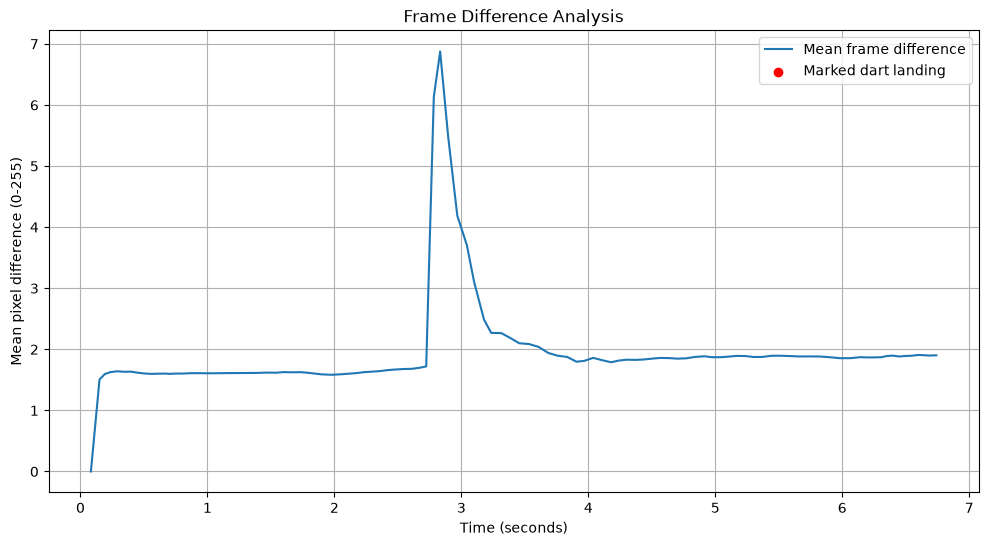

In [6]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("frame_differences.csv")

plt.figure(figsize=(12, 6))

plt.plot(
    df["time"],
    df["mean_difference"],
    label="Mean frame difference"
)

# Mark dart landing events
dart_events = df[df["dart_landed"] == 1]

plt.scatter(
    dart_events["time"],
    dart_events["mean_difference"],
    color="red",
    label="Marked dart landing",
    zorder=5
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean pixel difference (0-255)")
plt.title("Frame Difference Analysis")
plt.legend()
plt.grid(True)
plt.show()
